# 🚀 Master Guide: Agentic Workflows with LangGraph & LLMs

> **Comprehensive Reference & Masterclass**: Combining All Core Agentic Workflow Patterns, Production Examples, and Advanced Paradigms (Prompt Chaining, Parallelization, Semantic Routing, Orchestrator-Worker, Evaluator-Optimizer, Human-in-the-Loop, and Composite Pipelines).

---

## 🧭 Why Workflows Over Fully Autonomous Agents?

In modern production AI systems (as highlighted by Anthropic and leading AI engineering research), **predictable, constrained workflows** often outperform unconstrained autonomous agent loops. 

| Dimension | Autonomous Agents | Agentic Workflows |
| :--- | :--- | :--- |
| **Control & Determinism** | Low to Medium (LLM decides next steps dynamically) | High (Developer defines state graph and transitions) |
| **Token Cost & Latency** | Unpredictable (can enter loops or excessive tool calls) | Bounded and optimized |
| **Debugging & Auditing** | Difficult (state and reasoning drift) | Straightforward (deterministic state snapshots) |
| **Safety & Guardrails** | Complex runtime monitoring needed | Native guardrails, interrupts, and static review gates |
| **Ideal Use Cases** | Open-ended research, dynamic software exploration | Mission-critical pipelines, enterprise SLAs, triage |

<div align="center">

![Agentic Workflow Taxonomy](diagrams/0_taxonomy.png)

</div>

<details><summary>🔍 <b>View Mermaid Architecture Code</b></summary>

```mermaid
flowchart LR
    classDef main fill:#EBF5FB,stroke:#2980B9,stroke-width:2px,color:#1B4F72,font-weight:bold;
    classDef pattern fill:#E8F8F5,stroke:#1ABC9C,stroke-width:2px,color:#0E6251;
    classDef hitl fill:#FDEDEC,stroke:#E74C3C,stroke-width:2px,color:#78281F,font-weight:bold;
    classDef composite fill:#FEF9E7,stroke:#F39C12,stroke-width:2px,color:#7E5109,font-weight:bold;

    User([Input Request]) --> Tax[Workflow Taxonomy]:::main
    
    Tax --> P1[1. Prompt Chaining]:::pattern
    Tax --> P2[2. Parallelization]:::pattern
    Tax --> P3[3. Semantic Routing]:::pattern
    Tax --> P4[4. Orchestrator-Worker]:::pattern
    Tax --> P5[5. Evaluator-Optimizer]:::pattern
    Tax --> P6[6. Human-in-the-Loop HITL]:::hitl
    Tax --> P7[7. Composite Architecture]:::composite

    P1 --> Out([Structured High-Reliability Result]):::main
    P2 --> Out
    P3 --> Out
    P4 --> Out
    P5 --> Out
    P6 --> Out
    P7 --> Out
linkStyle default stroke:#ffffff,stroke-width:2px;
```
</details>



---
## ⚙️ 0. Environment Setup & Centralized LLM Configuration

All workflows in this notebook leverage the centralized `llm_config.py` module. This guarantees:
1. **Configurable Model Catalog**: Primary model defaults to `openai/gpt-oss-120b` (or active `.env` selection).
2. **Automatic Fallback Chaining**: Gracefully falls back across free Groq models (`qwen/qwen3.8-27b`, `openai/gpt-oss-20b`) if rate limits or outages occur.
3. **Consistent Visualization Utilities**: Standardized helper for rendering LangGraph graphs via Mermaid PNG with fallback to ASCII.



In [11]:
import os
from typing import Dict, List, Any, Optional, TypedDict, Annotated
import operator
from pydantic import BaseModel, Field

# Centralized LLM configuration with automatic multi-model fallbacks
from llm_config import get_llm, list_free_models

# LangGraph core primitives
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send, interrupt, Command
from langgraph.checkpoint.memory import MemorySaver

from IPython.display import Image, display

# Initialize our shared LLM instance
llm = get_llm()
print("[OK] LLM Initialized successfully!")
print(f"  Active Model: {getattr(llm, 'model_name', getattr(llm, 'model', 'default'))}")
print(f"  Fallback Enabled: {os.getenv('LLM_ENABLE_FALLBACKS', 'True')}")

def visualize_graph(compiled_graph):
    """Helper to display LangGraph architecture with graceful fallbacks."""
    try:
        display(Image(compiled_graph.get_graph().draw_mermaid_png()))
    except Exception:
        try:
            print(compiled_graph.get_graph().draw_ascii())
        except Exception:
            print(compiled_graph.get_graph().draw_mermaid())



[OK] LLM Initialized successfully!
  Active Model: qwen/qwen3.8-27b
  Fallback Enabled: True


---
## 🔗 Pattern 1: Prompt Chaining (Sequential Pipeline)

### Conceptual Architecture
In **Prompt Chaining**, a complex task is decomposed into a fixed sequence of discrete LLM processing steps. Each step takes the output of the preceding step as its input.

<div align="center">

![Pattern 1: Prompt Chaining](diagrams/1_prompt_chaining.png)

</div>

<details><summary>🔍 <b>View Mermaid Architecture Code</b></summary>

```mermaid
flowchart LR
    classDef startNode fill:#EBF5FB,stroke:#2980B9,stroke-width:2px,color:#1B4F72;
    classDef procNode fill:#E8F8F5,stroke:#16A085,stroke-width:2px,color:#0E6251;
    classDef endNode fill:#EAFAF1,stroke:#27AE60,stroke-width:2px,color:#145A32;

    START([Raw Incident Data]):::startNode --> Node1[Step 1: Incident Log Triage]:::procNode
    Node1 --> Node2[Step 2: Root Cause & Blast Radius]:::procNode
    Node2 --> Node3[Step 3: Executive Action Plan]:::procNode
    Node3 --> END([Published Postmortem]):::endNode
linkStyle default stroke:#ffffff,stroke-width:2px;
```
</details>

### Production Example: Enterprise Cloud Incident Postmortem Pipeline
- **Step 1: Incident Log Triage** - Extracts affected microservices, error spikes, and duration from raw telemetry logs.
- **Step 2: Root Cause & Blast Radius Analysis** - Identifies failure triggers and technical impact.
- **Step 3: Executive Postmortem & Runbook Action Plan** - Synthesizes non-technical executive summary and concrete SRE prevention tasks.



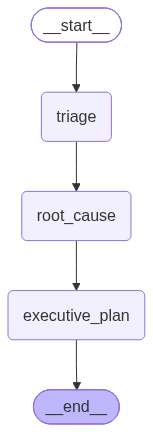

In [12]:
# --- Pattern 1 Implementation: Enterprise Incident Postmortem Pipeline ---

class IncidentState(TypedDict):
    raw_telemetry: str
    triage_summary: str
    root_cause_analysis: str
    executive_action_plan: str

def triage_node(state: IncidentState) -> Dict[str, Any]:
    """Step 1: Extract telemetry facts, timeline, and affected services."""
    prompt = (
        "You are an SRE Incident Commander. In under 80 words, triage these telemetry logs. "
        "Extract: 1) Affected microservices, 2) Timeline of failure, 3) Error codes observed.\n\n"
        f"Raw Logs:\n{state['raw_telemetry']}"
    )
    response = llm.invoke(prompt)
    return {"triage_summary": response.content}

def root_cause_node(state: IncidentState) -> Dict[str, Any]:
    """Step 2: Determine root cause and failure chain based on triage summary."""
    prompt = (
        "You are a Principal Infrastructure Architect. Based on this triage summary, "
        "in under 80 words identify root cause and blast radius.\n\n"
        f"Triage Summary:\n{state['triage_summary']}"
    )
    response = llm.invoke(prompt)
    return {"root_cause_analysis": response.content}

def executive_plan_node(state: IncidentState) -> Dict[str, Any]:
    """Step 3: Create executive summary and concrete SRE action items."""
    prompt = (
        "In under 100 words, generate a production postmortem report with:\n"
        "1. Executive Summary (non-technical leadership)\n"
        "2. Immediate Containment actions taken\n"
        "3. Long-term Prevention Runbook items.\n\n"
        f"Root Cause Analysis:\n{state['root_cause_analysis']}"
    )
    response = llm.invoke(prompt)
    return {"executive_action_plan": response.content}

# Build LangGraph Pipeline
p1_builder = StateGraph(IncidentState)
p1_builder.add_node("triage", triage_node)
p1_builder.add_node("root_cause", root_cause_node)
p1_builder.add_node("executive_plan", executive_plan_node)

p1_builder.add_edge(START, "triage")
p1_builder.add_edge("triage", "root_cause")
p1_builder.add_edge("root_cause", "executive_plan")
p1_builder.add_edge("executive_plan", END)

p1_graph = p1_builder.compile()
visualize_graph(p1_graph)



In [13]:
# Run Pattern 1 Demo
sample_logs = """
2026-10-12 14:02:11 UTC [orders-service] WARN: DB Connection pool usage at 94%
2026-10-12 14:03:05 UTC [payment-gateway] ERROR: HTTP 504 Gateway Timeout to Stripe Webhook
2026-10-12 14:03:22 UTC [orders-service] FATAL: ConnectionTimeoutException - pool exhausted (max: 200)
2026-10-12 14:04:10 UTC [ingress-nginx] 502 Bad Gateway spike across /checkout endpoints (4,200 req/min)
2026-10-12 14:15:00 UTC [sre-automation] Auto-scaled connection pool to 500, restarted stuck pods
"""

p1_result = p1_graph.invoke({"raw_telemetry": sample_logs})
print("=== TRIAGE SUMMARY ===")
print(p1_result["triage_summary"][:300] + "...\n")
print("=== EXECUTIVE ACTION PLAN ===")
print(p1_result["executive_action_plan"][:500] + "...")



=== TRIAGE SUMMARY ===
**1) Affected Microservices:** orders-service, payment-gateway, ingress-nginx.
**2) Timeline of Failure:**
- 14:02:11: DB pool warning (94%).
- 14:03:05: Payment gateway timeouts.
- 14:03:22: orders-service pool exhausted (FATAL).
- 14:04:10: Ingress 502 spikes on /checkout.
- 14:15:00: Auto-recover...

=== EXECUTIVE ACTION PLAN ===
**Executive Summary:** A critical database bottleneck caused a 13-minute checkout outage, blocking all customer transactions.

**Immediate Containment:**
1. Restarted exhausted database pods to clear stuck connections.
2. Scaled up order-service replicas to absorb backlog.
3. Verified payment-gateway latency returned to nominal.

**Long-Term Prevention Runbook:**
1. Increase `max_pool_size` by 50% and implement dynamic scaling.
2. Add circuit breakers to prevent synchronous cascading failures.
3...


---
## ⚡ Pattern 2: Parallelization (Sectioning & Guardrail Voting)

### Conceptual Architecture
In **Parallelization**, an input is processed concurrently across multiple nodes. There are two primary sub-patterns:
1. **Sectioning**: Splitting a task into independent sub-domains (e.g., Security, Performance, Compliance) analyzed in parallel, then synthesized.
2. **Voting / Guardrailing**: Running multiple independent prompts or models on the same task to achieve consensus or detect anomalies.

<div align="center">

![Pattern 2: Parallelization](diagrams/2_parallelization.png)

</div>

<details><summary>🔍 <b>View Mermaid Architecture Code</b></summary>

```mermaid
flowchart TD
    classDef startNode fill:#EBF5FB,stroke:#2980B9,stroke-width:2px,color:#1B4F72;
    classDef parNode fill:#F4ECF7,stroke:#8E44AD,stroke-width:2px,color:#512E5F;
    classDef aggNode fill:#FEF9E7,stroke:#F39C12,stroke-width:2px,color:#7E5109;
    classDef endNode fill:#EAFAF1,stroke:#27AE60,stroke-width:2px,color:#145A32;

    START([Release Proposal]):::startNode --> Fork{Fork Parallel Checks}
    Fork --> Sec[Security & Vulnerability Audit]:::parNode
    Fork --> Perf[Performance & Latency Audit]:::parNode
    Fork --> Comp[Regulatory & GDPR Compliance]:::parNode
    
    Sec --> Join{Join Results}
    Perf --> Join
    Comp --> Join
    
    Join --> Gate[Release Gatekeeper Synthesis]:::aggNode
    Gate --> END([Final Release Go/No-Go Decision]):::endNode
linkStyle default stroke:#ffffff,stroke-width:2px;
```
</details>

### Production Example: Multi-Perspective Product Release Gate
A pull request introducing an automated third-party analytics telemetry integration is evaluated concurrently by three specialist personas:
- **Security Auditor**: Checks credential exposure, data leakage, and MITM vectors.
- **Performance Auditor**: Evaluates query overhead, network latency, and memory footprint.
- **Compliance Auditor**: Assesses GDPR, PII consent, and privacy policy alignment.
All three parallel evaluations feed into a **Release Gatekeeper** that produces a unified Go/No-Go decision.



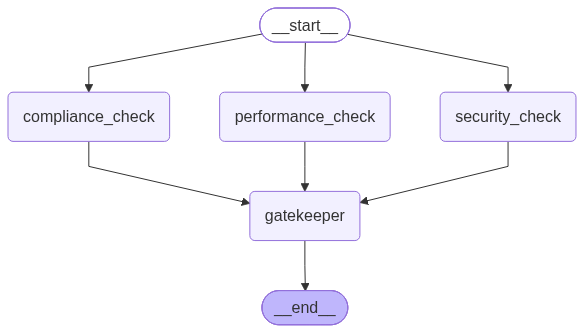

In [14]:
# --- Pattern 2 Implementation: Multi-Perspective Release Gate ---

class ReleaseGateState(TypedDict):
    feature_proposal: str
    security_audit: str
    performance_audit: str
    compliance_audit: str
    release_decision: str

def security_auditor_node(state: ReleaseGateState) -> Dict[str, Any]:
    """Parallel Worker 1: Security assessment."""
    prompt = (
        "You are a Lead Application Security Engineer. Audit this feature proposal for:\n"
        "- Credential leakage, authentication risks, and 3rd party dependency trust.\n"
        f"Proposal: {state['feature_proposal']}"
    )
    return {"security_audit": llm.invoke(prompt).content}

def performance_auditor_node(state: ReleaseGateState) -> Dict[str, Any]:
    """Parallel Worker 2: Performance and scalability assessment."""
    prompt = (
        "You are a Staff Performance Engineer. Audit this feature proposal for:\n"
        "- Latency impact, memory footprint, network overhead, and potential bottlenecks.\n"
        f"Proposal: {state['feature_proposal']}"
    )
    return {"performance_audit": llm.invoke(prompt).content}

def compliance_auditor_node(state: ReleaseGateState) -> Dict[str, Any]:
    """Parallel Worker 3: Legal & Privacy compliance."""
    prompt = (
        "You are a Data Privacy and Regulatory Officer. Audit this feature proposal for:\n"
        "- GDPR, PII handling, user tracking consent, and retention policies.\n"
        f"Proposal: {state['feature_proposal']}"
    )
    return {"compliance_audit": llm.invoke(prompt).content}

def release_gatekeeper_node(state: ReleaseGateState) -> Dict[str, Any]:
    """Aggregator Node: Consolidate parallel audits into final Go/No-Go verdict."""
    prompt = (
        "You are the Head of Engineering Release Gate. Synthesize the three independent audits below:\n\n"
        f"--- SECURITY AUDIT ---\n{state['security_audit']}\n\n"
        f"--- PERFORMANCE AUDIT ---\n{state['performance_audit']}\n\n"
        f"--- COMPLIANCE AUDIT ---\n{state['compliance_audit']}\n\n"
        "Provide:\n"
        "1. Executive Risk Score (1-10)\n"
        "2. Key Blockers\n"
        "3. Final Verdict: [APPROVED | APPROVED_WITH_CONDITIONS | BLOCKED]"
    )
    return {"release_decision": llm.invoke(prompt).content}

# Build Parallel StateGraph
p2_builder = StateGraph(ReleaseGateState)

p2_builder.add_node("security_check", security_auditor_node)
p2_builder.add_node("performance_check", performance_auditor_node)
p2_builder.add_node("compliance_check", compliance_auditor_node)
p2_builder.add_node("gatekeeper", release_gatekeeper_node)

# Fork from START to all 3 parallel nodes
p2_builder.add_edge(START, "security_check")
p2_builder.add_edge(START, "performance_check")
p2_builder.add_edge(START, "compliance_check")

# Join all 3 parallel nodes into gatekeeper
p2_builder.add_edge("security_check", "gatekeeper")
p2_builder.add_edge("performance_check", "gatekeeper")
p2_builder.add_edge("compliance_check", "gatekeeper")
p2_builder.add_edge("gatekeeper", END)

p2_graph = p2_builder.compile()
visualize_graph(p2_graph)



In [15]:
# Run Pattern 2 Demo
feature = """
Feature: Integrate Client-Side Session Replay SDK (FullStory/LogRocket alternative).
Details:
- Records user DOM mutations, mouse clicks, and keystrokes in real-time.
- Buffers sessions in browser IndexedDB and uploads gzip chunks to external AWS S3 bucket.
- Runs on every user interaction thread without debouncing.
- Captures input fields including billing forms, email, and user profiles.
"""

p2_result = p2_graph.invoke({"feature_proposal": feature})
print("=== RELEASE GATE DECISION ===")
print(p2_result["release_decision"][:600] + "...")



=== RELEASE GATE DECISION ===
**Head of Engineering – Release Gate – Synthesis of Security, Performance, and Compliance Audits**  
*Feature: Client‑side Session‑Replay SDK*  

---

## 1. Executive Risk Score  
**9 / 10**  

*Rationale*: The design simultaneously violates core security principles (credential leakage, lack of encryption, third‑party trust), creates a clear performance‑and‑availability liability (main‑thread blocking, unbounded memory use), and breaches multiple regulatory regimes (GDPR, CCPA/CPRA, PCI‑DSS, ePrivacy). The combination of high‑impact data‑exposure and systemic instability pushes the overall ris...


---
## 🔀 Pattern 3: Dynamic Semantic Routing (Intent Dispatcher)

### Conceptual Architecture
In **Routing**, an initial classifier node classifies an incoming request and directs it to the single most specialized downstream handler node or sub-pipeline. This prevents polluting specialized prompts with irrelevant domain logic.


<div align="center">

![Pattern 3](diagrams/3_semantic_routing.png)

</div>

<details><summary>🔍 <b>View Mermaid Architecture Code</b></summary>

```mermaid
%%{init: {'theme': 'base', 'themeVariables': { 'primaryColor': '#EBF5FB'}}}%%
flowchart TD
    classDef startNode fill:#EBF5FB,stroke:#2980B9,stroke-width:2px,color:#1B4F72;
    classDef routerNode fill:#FEF9E7,stroke:#F39C12,stroke-width:2px,color:#7E5109;
    classDef specNode fill:#E8F8F5,stroke:#16A085,stroke-width:2px,color:#0E6251;
    classDef endNode fill:#EAFAF1,stroke:#27AE60,stroke-width:2px,color:#145A32;

    START([Customer Inquiry]):::startNode --> Router[Semantic Intent Router]:::routerNode
    
    Router -->|billing| H1[Billing & Invoice Specialist]:::specNode
    Router -->|technical| H2[SRE & Technical Incident Specialist]:::specNode
    Router -->|policy_legal| H3[Legal & Terms Specialist]:::specNode
    Router -->|general| H4[General Support Specialist]:::specNode

    H1 --> END([Customer Resolution]):::endNode
    H2 --> END
    H3 --> END
    H4 --> END
linkStyle default stroke:#ffffff,stroke-width:2px;
```
</details>



### Production Example: Enterprise Customer Escalation & SLA Triage Router
Incoming support tickets are routed using structured output classification to appropriate specialized response handlers:
- **Billing**: Disputed charges, refund requests, tier upgrades.
- **Technical**: API downtime, 500 errors, SDK integration bugs.
- **Policy/Legal**: Data deletion, NDA inquiries, compliance certificates.
- **General**: Navigation, documentation, feature queries.




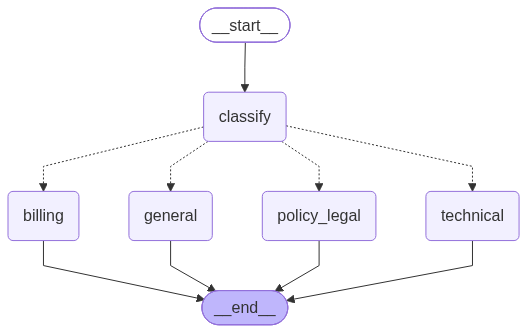

In [16]:
# --- Pattern 3 Implementation: Enterprise Support Router ---

class RouteIntent(BaseModel):
    category: str = Field(
        ..., 
        description="One of: 'billing', 'technical', 'policy_legal', 'general'"
    )
    confidence: float = Field(..., description="Confidence score from 0.0 to 1.0")
    reasoning: str = Field(..., description="Brief justification for classification")

class SupportTicketState(TypedDict):
    ticket_text: str
    intent: Optional[str]
    response: Optional[str]

def classify_intent_node(state: SupportTicketState) -> Dict[str, Any]:
    """Classifier: Uses structured output to determine ticket category."""
    classifier_llm = llm.with_structured_output(RouteIntent)
    prompt = (
        "Classify the following customer ticket into exactly one category: "
        "'billing', 'technical', 'policy_legal', or 'general'.\n\n"
        f"Ticket: {state['ticket_text']}"
    )
    intent_obj: RouteIntent = classifier_llm.invoke(prompt)
    return {"intent": intent_obj.category}

def billing_handler(state: SupportTicketState) -> Dict[str, Any]:
    prompt = f"You are a Tier-2 Billing Specialist. Address this inquiry with invoice clarity and empathy:\n{state['ticket_text']}"
    return {"response": f"[BILLING DESK] {llm.invoke(prompt).content}"}

def technical_handler(state: SupportTicketState) -> Dict[str, Any]:
    prompt = f"You are a Senior Technical Solutions Engineer. Address this issue with technical precision and troubleshooting steps:\n{state['ticket_text']}"
    return {"response": f"[TECH ESCALATION] {llm.invoke(prompt).content}"}

def policy_handler(state: SupportTicketState) -> Dict[str, Any]:
    prompt = f"You are a Legal & Compliance Officer. Address this inquiry adhering to strict terms of service and GDPR policy:\n{state['ticket_text']}"
    return {"response": f"[LEGAL & PRIVACY] {llm.invoke(prompt).content}"}

def general_handler(state: SupportTicketState) -> Dict[str, Any]:
    prompt = f"You are a Friendly Support Ambassador. Address this general question helpfully:\n{state['ticket_text']}"
    return {"response": f"[GENERAL CARE] {llm.invoke(prompt).content}"}

def route_decision(state: SupportTicketState) -> str:
    category = state.get("intent", "general")
    if category in ["billing", "technical", "policy_legal"]:
        return category
    return "general"

# Build Router Graph
p3_builder = StateGraph(SupportTicketState)
p3_builder.add_node("classify", classify_intent_node)
p3_builder.add_node("billing", billing_handler)
p3_builder.add_node("technical", technical_handler)
p3_builder.add_node("policy_legal", policy_handler)
p3_builder.add_node("general", general_handler)

p3_builder.add_edge(START, "classify")
p3_builder.add_conditional_edges(
    "classify",
    route_decision,
    {
        "billing": "billing",
        "technical": "technical",
        "policy_legal": "policy_legal",
        "general": "general"
    }
)

p3_builder.add_edge("billing", END)
p3_builder.add_edge("technical", END)
p3_builder.add_edge("policy_legal", END)
p3_builder.add_edge("general", END)

p3_graph = p3_builder.compile()
visualize_graph(p3_graph)



In [17]:
# Run Pattern 3 Demo with diverse tickets
sample_tickets = [
    "Our team was charged $1,450 twice for our enterprise subscription last Friday. We need an immediate refund and revised invoice.",
    "Our production webhook receiver is returning HTTP 500 when processing signature headers with SHA256 under high concurrency.",
    "We need a signed Data Processing Addendum (DPA) and confirmation of your SOC2 Type II audit report for our European entity."
]

for ticket in sample_tickets:
    result = p3_graph.invoke({"ticket_text": ticket})
    print(f"Ticket: {ticket[:60]}...")
    print(f"Routed Intent: {result['intent']}")
    print(f"Response: {result['response'][:180]}...\n")



Ticket: Our team was charged $1,450 twice for our enterprise subscri...
Routed Intent: billing
Response: [BILLING DESK] Subject: Urgent: Resolution for Duplicate Charge – Invoice #[Original Invoice Number]

Dear [Client Name],

I am sincerely sorry to hear about the duplicate charge o...

Ticket: Our production webhook receiver is returning HTTP 500 when p...
Routed Intent: technical
Response: [TECH ESCALATION] ## Executive Summary
The webhook receiver is throwing **HTTP 500** when it validates the `X‑Signature` (SHA‑256 HMAC) under **high concurrency**.  
A 500 indicate...

Ticket: We need a signed Data Processing Addendum (DPA) and confirma...
Routed Intent: policy_legal
Response: [LEGAL & PRIVACY] **Subject: Request for Data Processing Addendum (DPA) and SOC 2 Type II Audit Confirmation**

Dear [Client Name / European Entity Representative],

Thank you for ...



---
## 👑 Pattern 4: Orchestrator-Worker (Dynamic Map-Reduce via Send API)

### Conceptual Architecture
In the **Orchestrator-Worker** pattern, a central orchestrator LLM dynamically analyzes a complex problem, breaks it down into a variable number of independent subtasks, dispatches them to parallel workers (using LangGraph's `Send` API), and synthesizes worker outputs into a cohesive final deliverable.

Unlike static parallelization (Pattern 2), the number and nature of worker tasks are **not known ahead of time**; the orchestrator invents them on the fly.


<div align="center">

![Pattern 4](diagrams/4_orchestrator_worker.png)

</div>

<details><summary>🔍 <b>View Mermaid Architecture Code</b></summary>

```mermaid
%%{init: {'theme': 'base', 'themeVariables': { 'primaryColor': '#EBF5FB'}}}%%
flowchart TD
    classDef startNode fill:#EBF5FB,stroke:#2980B9,stroke-width:2px,color:#1B4F72;
    classDef orchNode fill:#FEF9E7,stroke:#F39C12,stroke-width:2px,color:#7E5109;
    classDef workerNode fill:#E8F8F5,stroke:#16A085,stroke-width:2px,color:#0E6251;
    classDef synthNode fill:#EAFAF1,stroke:#27AE60,stroke-width:2px,color:#145A32;

    START([Research Objective]):::startNode --> Orch[Orchestrator: Plan Subtasks]:::orchNode
    
    Orch -->|Send API Map| W1[Worker 1: Analysis Task A]:::workerNode
    Orch -->|Send API Map| W2[Worker 2: Analysis Task B]:::workerNode
    Orch -->|Send API Map| W3[Worker 3: Analysis Task C]:::workerNode

    W1 -->|Reducer: append| Synth[Synthesizer: Executive Briefing]:::synthNode
    W2 -->|Reducer: append| Synth
    W3 -->|Reducer: append| Synth

    Synth --> END([Strategic Report]):::synthNode
linkStyle default stroke:#ffffff,stroke-width:2px;
```
</details>



### Production Example: Dynamic Competitive Market Intelligence Generator
- **Orchestrator**: Dynamically identifies key competitive pillars (e.g., Pricing Strategy, Tech Stack, Enterprise GTM, Customer Retention) for a target market.
- **Workers (Dynamic Map)**: Each worker executes a deep dive on one specific pillar.
- **Synthesizer (Reduce)**: Gathers all worker analyses and produces an executive strategy matrix.




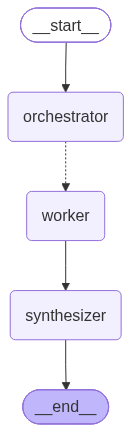

In [18]:
# --- Pattern 4 Implementation: Dynamic Market Intelligence ---

class SubTask(BaseModel):
    pillar_name: str = Field(..., description="Name of the strategic dimension/pillar")
    research_questions: List[str] = Field(..., description="Key questions to investigate")

class OrchestratorPlan(BaseModel):
    pillars: List[SubTask] = Field(..., description="List of dynamic subtasks to investigate")

class WorkerReport(TypedDict):
    pillar_name: str
    findings: str

class MarketResearchState(TypedDict):
    topic: str
    pillars: List[SubTask]
    worker_reports: Annotated[List[WorkerReport], operator.add]  # Reducer appends worker reports
    final_brief: str

def orchestrator_node(state: MarketResearchState) -> Dict[str, Any]:
    """Orchestrator: Breaks topic into 3 distinct strategic research pillars."""
    planner_llm = llm.with_structured_output(OrchestratorPlan)
    prompt = (
        f"You are a Chief Strategy Officer. Analyze this market sector: '{state['topic']}'.\n"
        "Break the analysis into exactly 2 critical strategic pillars (e.g., Pricing & Margins, "
        "Technological Moat, Enterprise Go-To-Market)."
    )
    plan: OrchestratorPlan = planner_llm.invoke(prompt)
    return {"pillars": plan.pillars}

def worker_node(task_payload: Dict[str, Any]) -> Dict[str, Any]:
    """Worker: Evaluates a single specific pillar dispatched via Send API."""
    pillar = task_payload["pillar"]
    topic = task_payload["topic"]
    
    prompt = (
        f"You are a Senior Industry Analyst. Conduct a deep dive on pillar '{pillar.pillar_name}' "
        f"for topic '{topic}'.\n"
        f"Focus on questions: {', '.join(pillar.research_questions)}.\n"
        "Provide actionable insights with concrete examples."
    )
    response = llm.invoke(prompt)
    return {
        "worker_reports": [{
            "pillar_name": pillar.pillar_name,
            "findings": response.content
        }]
    }

def synthesizer_node(state: MarketResearchState) -> Dict[str, Any]:
    """Synthesizer: Compiles all worker findings into an executive matrix."""
    compiled_findings = "\n\n".join([
        f"### Pillar: {r['pillar_name']}\n{r['findings']}"
        for r in state["worker_reports"]
    ])
    prompt = (
        f"You are an Executive Briefing Director. Synthesize these market research findings "
        f"on topic '{state['topic']}' in under 100 words into an Executive Strategic Brief:\n\n"
        f"{compiled_findings}"
    )
    response = llm.invoke(prompt)
    return {"final_brief": response.content}

def dispatch_workers(state: MarketResearchState) -> List[Send]:
    """Map Step: Dispatches a worker node for each planned pillar via Send API."""
    return [
        Send("worker", {"pillar": pillar, "topic": state["topic"]})
        for pillar in state["pillars"]
    ]

# Build Orchestrator-Worker StateGraph
p4_builder = StateGraph(MarketResearchState)
p4_builder.add_node("orchestrator", orchestrator_node)
p4_builder.add_node("worker", worker_node)
p4_builder.add_node("synthesizer", synthesizer_node)

p4_builder.add_edge(START, "orchestrator")
p4_builder.add_conditional_edges("orchestrator", dispatch_workers, ["worker"])
p4_builder.add_edge("worker", "synthesizer")
p4_builder.add_edge("synthesizer", END)

p4_graph = p4_builder.compile()
visualize_graph(p4_graph)



In [19]:
# Run Pattern 4 Demo
p4_result = p4_graph.invoke({
    "topic": "Vector Database Market in 2026 (Pinecone vs Qdrant vs pgvector)",
    "worker_reports": []
})

print(f"Generated {len(p4_result['worker_reports'])} worker pillar reports.")
for r in p4_result["worker_reports"]:
    print(f"- Pillar: {r['pillar_name']}")

print("\n=== SYNTHESIZED EXECUTIVE BRIEF ===")
print(p4_result["final_brief"][:500] + "...")



RateLimitError: Error code: 429 - {'error': {'message': "Request too large for model `qwen/qwen3.8-27b` in organization `org_01m0754txtetft6mp668qjxk9r` service tier `on_demand` on output tokens per minute (OTPM): Limit 1000, Requested 1307. The request's expected output tokens exceed the enforced limit; reduce max_tokens (or the request's expected output) and try again. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing", 'type': 'tokens', 'code': 'rate_limit_exceeded'}}

---
## 🔄 Pattern 5: Evaluator-Optimizer (Self-Correction & Refinement Loop)

### Conceptual Architecture
In the **Evaluator-Optimizer** pattern, one LLM component produces a candidate solution, and a separate **Evaluator** LLM component scores it against a strict objective rubric. If the solution does not pass, structured feedback is looped back into the optimizer/generator for iterative refinement until it passes or hits max iterations.

> **Design Principle**: We strictly refer to the feedback entity as the **Evaluator** (evaluating quality, alignment, and correctness).


<div align="center">

![Pattern 5](diagrams/5_evaluator_optimizer.png)

</div>

<details><summary>🔍 <b>View Mermaid Architecture Code</b></summary>

```mermaid
%%{init: {'theme': 'base', 'themeVariables': { 'primaryColor': '#EBF5FB'}}}%%
flowchart TD
    classDef startNode fill:#EBF5FB,stroke:#2980B9,stroke-width:2px,color:#1B4F72;
    classDef genNode fill:#E8F8F5,stroke:#16A085,stroke-width:2px,color:#0E6251;
    classDef evalNode fill:#FEF9E7,stroke:#F39C12,stroke-width:2px,color:#7E5109;
    classDef passNode fill:#EAFAF1,stroke:#27AE60,stroke-width:2px,color:#145A32;

    START([Specification]):::startNode --> Gen[Generator: Draft Solution]:::genNode
    Gen --> Eval[Evaluator: Grade against Rubric]:::evalNode
    
    Eval --> Check{Score >= 85 or Max Loops?}
    Check -->|Needs Refinement| Gen
    Check -->|Passed Rubric| END([Production-Ready Deliverable]):::passNode
linkStyle default stroke:#ffffff,stroke-width:2px;
```
</details>



### Production Example: High-Reliability Python Utility Generator with Static Rubric
- **Generator**: Implements a complex Python function satisfying user requirements.
- **Evaluator**: Grades the implementation against a rigorous 4-part rubric:
  1. *Functional correctness*
  2. *Strict PEP 484 type hints*
  3. *Google-style docstrings with edge case notes*
  4. *Robust error handling & bounds checking*
- **Optimizer Loop**: Refines iteratively until a score >= 85 is achieved or max iterations (3) is reached.




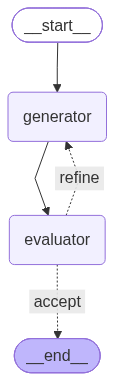

In [ ]:
# --- Pattern 5 Implementation: Evaluator-Optimizer ---

class EvaluationRubric(BaseModel):
    score: int = Field(..., description="Overall score between 0 and 100")
    passed: bool = Field(..., description="True if score >= 85")
    critique_points: List[str] = Field(..., description="Actionable points for improvement")

class CodeGenState(TypedDict):
    specification: str
    current_code: str
    iteration: int
    eval_score: int
    feedback: str

def generator_node(state: CodeGenState) -> Dict[str, Any]:
    """Generator: Writes or refines code based on Evaluator feedback."""
    iteration = state.get("iteration", 0) + 1
    feedback = state.get("feedback", "")
    
    if not feedback:
        prompt = (
            f"Write a production-grade Python function for this specification:\n{state['specification']}\n"
            "Requirements: Complete typing, Google docstring, defensive error checking."
        )
    else:
        prompt = (
            f"Refine this Python code to address the Evaluator's feedback:\n\n"
            f"Specification: {state['specification']}\n\n"
            f"Current Code:\n{state['current_code']}\n\n"
            f"Evaluator Feedback:\n{feedback}\n\n"
            "Produce the complete improved Python code only."
        )
    
    response = llm.invoke(prompt)
    return {
        "current_code": response.content,
        "iteration": iteration
    }

def evaluator_node(state: CodeGenState) -> Dict[str, Any]:
    """Evaluator: Scores code against rigorous engineering quality rubric."""
    evaluator_llm = llm.with_structured_output(EvaluationRubric)
    prompt = (
        "Evaluate the following Python code against this 4-point rubric:\n"
        "1. Complete functional correctness\n"
        "2. Strict PEP 484 type annotations on all signatures\n"
        "3. Google-style docstring with Args, Returns, and Raises\n"
        "4. Defensive exception handling (ValueError/TypeError)\n\n"
        f"Code:\n{state['current_code']}"
    )
    eval_result: EvaluationRubric = evaluator_llm.invoke(prompt)
    feedback_str = f"Score: {eval_result.score}/100. Issues: " + "; ".join(eval_result.critique_points)
    
    return {
        "eval_score": eval_result.score,
        "feedback": feedback_str
    }

def evaluator_router(state: CodeGenState) -> str:
    """Route: Terminate if passed (score >= 85) or max iterations reached."""
    if state["eval_score"] >= 85 or state["iteration"] >= 3:
        return "accept"
    return "refine"

# Build Evaluator-Optimizer Graph
p5_builder = StateGraph(CodeGenState)
p5_builder.add_node("generator", generator_node)
p5_builder.add_node("evaluator", evaluator_node)

p5_builder.add_edge(START, "generator")
p5_builder.add_edge("generator", "evaluator")
p5_builder.add_conditional_edges(
    "evaluator",
    evaluator_router,
    {
        "refine": "generator",
        "accept": END
    }
)

p5_graph = p5_builder.compile()
visualize_graph(p5_graph)



In [ ]:
# Run Pattern 5 Demo
p5_result = p5_graph.invoke({
    "specification": "Create an async rate-limiter class using a Token Bucket algorithm with millisecond precision and thread-safe lock acquisition.",
    "current_code": "",
    "iteration": 0,
    "eval_score": 0,
    "feedback": ""
})

print(f"Completed in {p5_result['iteration']} iteration(s).")
print(f"Final Evaluator Score: {p5_result['eval_score']}/100")
print(f"Evaluator Feedback: {p5_result['feedback']}")
print("\n=== GENERATED CODE ===")
print(p5_result["current_code"][:500] + "...")



Completed in 1 iteration(s).
Final Evaluator Score: 88/100
Evaluator Feedback: Score: 88/100. Issues: The implementation is largely correct, but the comment in `_refresh` claiming a *non‑blocking* lock acquisition is misleading – the lock is still acquired in a blocking fashion inside the executor thread, and the lock is released before the method returns, so the subsequent read in `available_tokens` is not protected.; `available_tokens` reads `_tokens` after `_refresh` has released the lock, introducing a tiny race condition if another thread modifies the state concurrently.; Input validation for `acquire` does not check the type or sign of the optional `timeout` argument; a negative timeout or a non‑numeric value should raise a `ValueError` or `TypeError`.; Only `ValueError` is raised for type mismatches; the rubric expects defensive handling with both `ValueError` and `TypeError` where appropriate.; The docstring for the private method `_refresh` is present but does not follow the f

---
## 👤 Pattern 6: Human-in-the-Loop (HITL) Workflow (The Crucial Missed Topic)

### Why Human-in-the-Loop is Mission-Critical
In real-world enterprise agent deployments, autonomous workflows **must not** perform high-impact or destructive actions (such as initiating financial refunds, dropping database tables, emailing customers, or deploying code) without explicit human oversight.

LangGraph provides native Human-in-the-Loop primitives:
1. **Checkpointers (`MemorySaver`, database checkpointers)**: Persist graph state at every step under a `thread_id`.
2. **`interrupt()`**: Pauses graph execution mid-step, emits payload to the user/UI, and waits.
3. **`Command(resume=...)`**: Injects human decisions, reviews, or edited parameters back into the paused state.


<div align="center">

![Pattern 6](diagrams/6_human_in_the_loop.png)

</div>

<details><summary>🔍 <b>View Mermaid Architecture Code</b></summary>

```mermaid
%%{init: {'theme': 'base', 'themeVariables': { 'primaryColor': '#FDEDEC'}}}%%
flowchart LR
    classDef startNode fill:#EBF5FB,stroke:#2980B9,stroke-width:2px,color:#1B4F72;
    classDef prepNode fill:#E8F8F5,stroke:#16A085,stroke-width:2px,color:#0E6251;
    classDef pauseNode fill:#FDEDEC,stroke:#E74C3C,stroke-width:3px,color:#78281F,font-weight:bold;
    classDef humanNode fill:#FEF9E7,stroke:#F39C12,stroke-width:2px,color:#7E5109;
    classDef execNode fill:#EAFAF1,stroke:#27AE60,stroke-width:2px,color:#145A32;

    START([Refund Request]):::startNode --> Prep[Agent: Assess Risk & Draft Refund]:::prepNode
    Prep --> Gate{Risk > Threshold?}
    
    Gate -->|Yes: Sensitive| Pause[interrupt: Halt Execution]:::pauseNode
    Pause -.->|Await Review| Human([Human Compliance Officer]):::humanNode
    Human -.->|Command resume: Approved| Resume[Resume Execution]:::execNode
    
    Gate -->|No: Low Risk| Exec[Auto-Execute]:::execNode
    Resume --> Exec
    Exec --> END([Audit Ledger Updated]):::execNode
linkStyle default stroke:#ffffff,stroke-width:2px;
```
</details>



### Production Example: High-Value Financial Refund Gate
1. **Agent Draft**: Ingests refund claim, evaluates account history, and drafts a proposed refund transaction.
2. **Human Approval Gate**: Graph calls `interrupt()`, halting execution and prompting a human compliance officer.
3. **Human Action**: Compliance officer reviews details, can approve, reject, or adjust the approved refund amount.
4. **Resumed Execution**: Graph resumes seamlessly via `Command(resume=...)` and commits the transaction to the ledger.




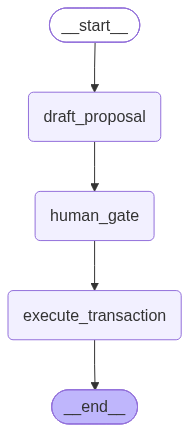

In [ ]:
# --- Pattern 6 Implementation: Human-in-the-Loop Refund Approval ---

class RefundTransaction(BaseModel):
    account_id: str
    claimed_amount: float
    recommended_amount: float
    fraud_risk_score: float = Field(..., description="Score 0.0 to 1.0")
    reasoning: str

class HITLState(TypedDict):
    account_id: str
    claim_reason: str
    claim_amount: float
    transaction_proposal: Optional[Dict[str, Any]]
    human_verdict: Optional[Dict[str, Any]]
    final_execution_status: Optional[str]

def draft_proposal_node(state: HITLState) -> Dict[str, Any]:
    """Step 1: AI Agent drafts financial proposal and evaluates risk."""
    prompt = (
        f"You are a Fraud Risk Assessment AI. Analyze this refund claim:\n"
        f"Account ID: {state['account_id']}\n"
        f"Claimed Amount: ${state['claim_amount']}\n"
        f"Reason: {state['claim_reason']}\n\n"
        "Provide structured assessment with recommended refund amount and risk score."
    )
    draft_llm = llm.with_structured_output(RefundTransaction)
    proposal: RefundTransaction = draft_llm.invoke(prompt)
    return {"transaction_proposal": proposal.dict()}

def human_review_gate_node(state: HITLState) -> Dict[str, Any]:
    """Step 2: Pauses execution with interrupt() to request human approval."""
    proposal = state["transaction_proposal"]
    
    # Trigger LangGraph interrupt - halting execution
    human_decision = interrupt({
        "action_required": "HIGH_VALUE_REFUND_APPROVAL",
        "account_id": proposal["account_id"],
        "recommended_amount": proposal["recommended_amount"],
        "fraud_risk_score": proposal["fraud_risk_score"],
        "prompt": "Please review and approve, adjust amount, or reject."
    })
    
    return {"human_verdict": human_decision}

def execute_transaction_node(state: HITLState) -> Dict[str, Any]:
    """Step 3: Commits the approved transaction or records rejection."""
    verdict = state.get("human_verdict", {})
    status = verdict.get("decision", "REJECTED")
    amount = verdict.get("approved_amount", 0.0)
    
    if status == "APPROVED":
        msg = f"SUCCESS: Processed payout of ${amount:.2f} to account {state['account_id']} with auditor notes: {verdict.get('notes')}"
    else:
        msg = f"BLOCKED: Refund rejected by compliance officer. Notes: {verdict.get('notes')}"
        
    return {"final_execution_status": msg}

# Build HITL StateGraph
p6_builder = StateGraph(HITLState)
p6_builder.add_node("draft_proposal", draft_proposal_node)
p6_builder.add_node("human_gate", human_review_gate_node)
p6_builder.add_node("execute_transaction", execute_transaction_node)

p6_builder.add_edge(START, "draft_proposal")
p6_builder.add_edge("draft_proposal", "human_gate")
p6_builder.add_edge("human_gate", "execute_transaction")
p6_builder.add_edge("execute_transaction", END)

# Checkpointer is REQUIRED for HITL interrupt/resume
checkpointer = MemorySaver()
p6_graph = p6_builder.compile(checkpointer=checkpointer)
visualize_graph(p6_graph)



In [ ]:
# Run Pattern 6 Demo: Step-by-Step Interrupt & Resume Execution

thread_config = {"configurable": {"thread_id": "refund-audit-thread-902"}}

# 1. Initiate workflow until human interrupt occurs
initial_state = {
    "account_id": "ACC-99824",
    "claim_amount": 4500.0,
    "claim_reason": "Charged for 3 unused enterprise seat licenses during enterprise contract renewal."
}

print("-> Starting workflow...")
partial_result = p6_graph.invoke(initial_state, config=thread_config)

# Check what interrupt occurred
interrupts = partial_result.get("__interrupt__", [])
print(f"-> Workflow paused! Interrupt emitted: {interrupts}")

# 2. Simulate Human Review & Decision
human_compliance_approval = {
    "decision": "APPROVED",
    "approved_amount": 4200.0,
    "notes": "Verified billing audit logs. Partial credit approved for 3 seats minus 10% processing fee."
}

print("\n-> Resuming workflow with Human Command...")
final_result = p6_graph.invoke(
    Command(resume=human_compliance_approval),
    config=thread_config
)

print("\n=== FINAL EXECUTION RESULT ===")
print(final_result["final_execution_status"])



-> Starting workflow...
-> Workflow paused! Interrupt emitted: [Interrupt(value={'action_required': 'HIGH_VALUE_REFUND_APPROVAL', 'account_id': 'ACC-99824', 'recommended_amount': 3000.0, 'fraud_risk_score': 0.35, 'prompt': 'Please review and approve, adjust amount, or reject.'}, id='b0c57c4c61554c986a27d94b22295a2a')]

-> Resuming workflow with Human Command...

=== FINAL EXECUTION RESULT ===
SUCCESS: Processed payout of $4200.00 to account ACC-99824 with auditor notes: Verified billing audit logs. Partial credit approved for 3 seats minus 10% processing fee.


---
## 🧩 Pattern 7: Composite Hybrid Workflow (Enterprise Architecture)

### Conceptual Architecture
In production systems, workflows are rarely isolated into a single textbook pattern. A **Composite Hybrid Workflow** seamlessly links multiple patterns into an end-to-end mission-critical pipeline:

1. **Routing**: Directs user request to the right domain pipeline.
2. **Parallel Verification**: Multiple checks run concurrently.
3. **Evaluator-Optimizer**: Solution is iteratively refined against quality criteria.
4. **Human-in-the-Loop**: High-risk actions pause for final human sign-off.


<div align="center">

![Pattern 7](diagrams/7_composite_architecture.png)

</div>

<details><summary>🔍 <b>View Mermaid Architecture Code</b></summary>

```mermaid
%%{init: {'theme': 'base', 'themeVariables': { 'primaryColor': '#FEF9E7'}}}%%
flowchart TD
    classDef startNode fill:#EBF5FB,stroke:#2980B9,stroke-width:2px,color:#1B4F72;
    classDef routerNode fill:#FEF9E7,stroke:#F39C12,stroke-width:2px,color:#7E5109;
    classDef parNode fill:#F4ECF7,stroke:#8E44AD,stroke-width:2px,color:#512E5F;
    classDef evalNode fill:#E8F8F5,stroke:#16A085,stroke-width:2px,color:#0E6251;
    classDef hitlNode fill:#FDEDEC,stroke:#E74C3C,stroke-width:2px,color:#78281F,font-weight:bold;
    classDef endNode fill:#EAFAF1,stroke:#27AE60,stroke-width:2px,color:#145A32;

    START([Inbound Engineering Request]):::startNode --> Router[1. Semantic Router]:::routerNode
    
    Router -->|Feature Request| Fork{2. Parallel Security & Architecture Audit}
    Fork --> Sec[Security Audit]:::parNode
    Fork --> Arch[Architecture Audit]:::parNode
    
    Sec --> Join{Join}
    Arch --> Join
    
    Join --> Loop[3. Evaluator-Optimizer Synthesis]:::evalNode
    Loop --> Check{Approved?}
    Check -->|Needs Fix| Loop
    Check -->|Pass| SignOff[4. HITL Director Sign-Off]:::hitlNode
    
    SignOff --> END([Production Deployment]):::endNode
linkStyle default stroke:#ffffff,stroke-width:2px;
```
</details>



### Production Example: Enterprise Software Change Advisory Board (CAB) Pipeline
Combines:
- **Router**: Filters operational changes vs. architecture changes.
- **Parallel Workers**: Audits security exposure and infrastructure dependencies.
- **Evaluator**: Verifies change runbook meets strict deployment rubric.
- **HITL Checkpoint**: CAB chairperson reviews final synthesized plan and authorizes merge.




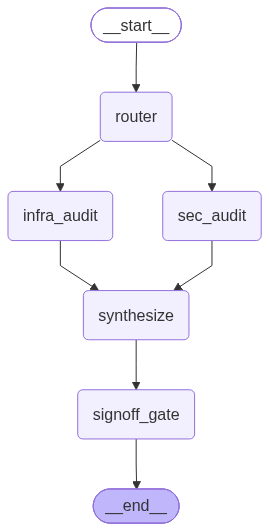

In [ ]:
# --- Pattern 7 Implementation: Composite CAB Pipeline ---

class CompositeCABState(TypedDict):
    change_title: str
    change_type: str
    security_verdict: str
    infra_verdict: str
    runbook_plan: str
    evaluator_approved: bool
    cab_chair_signoff: Optional[str]

def cab_router_node(state: CompositeCABState) -> Dict[str, Any]:
    """Step 1: Classifies change priority."""
    return {"change_type": "MAJOR_INFRASTRUCTURE_MIGRATION"}

def cab_sec_audit(state: CompositeCABState) -> Dict[str, Any]:
    """Step 2a: Parallel Security Audit."""
    prompt = f"Security audit for change: {state['change_title']}"
    return {"security_verdict": llm.invoke(prompt).content[:150]}

def cab_infra_audit(state: CompositeCABState) -> Dict[str, Any]:
    """Step 2b: Parallel Infra Audit."""
    prompt = f"Infrastructure capacity audit for change: {state['change_title']}"
    return {"infra_verdict": llm.invoke(prompt).content[:150]}

def cab_synthesizer_node(state: CompositeCABState) -> Dict[str, Any]:
    """Step 3: Synthesizes audits into deployment runbook."""
    prompt = (
        f"Create concise deployment runbook combining:\n"
        f"Security: {state['security_verdict']}\n"
        f"Infra: {state['infra_verdict']}"
    )
    return {
        "runbook_plan": llm.invoke(prompt).content[:250],
        "evaluator_approved": True
    }

def cab_signoff_gate(state: CompositeCABState) -> Dict[str, Any]:
    """Step 4: HITL Human Gate for CAB Chairperson authorization."""
    approval = interrupt({
        "msg": "CAB Authorization Required",
        "change": state["change_title"],
        "plan_summary": state["runbook_plan"]
    })
    return {"cab_chair_signoff": f"Signed off by {approval.get('approver')}"}

# Build Composite Graph
p7_builder = StateGraph(CompositeCABState)
p7_builder.add_node("router", cab_router_node)
p7_builder.add_node("sec_audit", cab_sec_audit)
p7_builder.add_node("infra_audit", cab_infra_audit)
p7_builder.add_node("synthesize", cab_synthesizer_node)
p7_builder.add_node("signoff_gate", cab_signoff_gate)

p7_builder.add_edge(START, "router")
p7_builder.add_edge("router", "sec_audit")
p7_builder.add_edge("router", "infra_audit")
p7_builder.add_edge("sec_audit", "synthesize")
p7_builder.add_edge("infra_audit", "synthesize")
p7_builder.add_edge("synthesize", "signoff_gate")
p7_builder.add_edge("signoff_gate", END)

composite_checkpointer = MemorySaver()
p7_graph = p7_builder.compile(checkpointer=composite_checkpointer)
visualize_graph(p7_graph)



In [ ]:
# Run Pattern 7 Demo
cab_thread = {"configurable": {"thread_id": "cab-ticket-4401"}}

res_initial = p7_graph.invoke(
    {"change_title": "Migrate Primary Postgres cluster to Aurora Multi-Region"},
    config=cab_thread
)
print("-> Composite workflow reached Human Approval Gate:")
print(res_initial.get("__interrupt__"))

# Resume with Chairperson signature
res_final = p7_graph.invoke(
    Command(resume={"approver": "Dr. Sarah Chen, VP Infrastructure"}),
    config=cab_thread
)
print("\n=== FINAL CAB STATUS ===")
print(res_final["cab_chair_signoff"])



-> Composite workflow reached Human Approval Gate:
[Interrupt(value={'msg': 'CAB Authorization Required', 'change': 'Migrate Primary Postgres cluster to Aurora Multi-Region', 'plan_summary': '# 📘 Deployment Runbook  \n**Project:** Migration of Primary PostgreSQL Cluster → Amazon Aurora PostgreSQL (Multi‑Region)  \n**Prepared for:** *\\<Your Organization>*  \n**Prepared by:** *Infrastructure & Security Teams*  \n**Version:** 1.0\u202f|\u202fDate:\u202f2026‑10'}, id='504186b5a79b2d160cd6d86b9042d975')]

=== FINAL CAB STATUS ===
Signed off by Dr. Sarah Chen, VP Infrastructure


---
## 📊 8. Architectural Decision Matrix: Which Pattern When?

Use this decision matrix to determine the optimal workflow pattern for your enterprise application:

| Pattern | Latency | Token Cost | Determinism | Best Suited For | Avoid When |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Prompt Chaining** | Medium (Linear) | Low | High | Step-by-step transformations, log postmortems, multi-stage summarization | Tasks that can be solved in a single prompt |
| **Parallelization** | Fast (Concurrent) | Medium | High | Independent multi-perspective checks, security/compliance audits, voting | Steps that have strict sequential dependencies |
| **Semantic Routing** | Low | Very Low | High | Triage, customer support ticket dispatching, multilingual queries | Highly ambiguous or hybrid requests needing multiple branches |
| **Orchestrator-Worker** | Medium to High | High | Medium | Open-domain research, dynamic map-reduce over unknown sub-tasks | Problems where sub-tasks are known statically ahead of time |
| **Evaluator-Optimizer** | High (Iterative) | High | High | Code generation, strict rubric scoring, mathematical reasoning | Latency-critical real-time chat APIs |
| **Human-in-the-Loop** | Asynchronous | Low | Absolute | High-value payments, destructive migrations, compliance approvals | High-frequency low-risk actions where human adds no value |
| **Composite Hybrid** | Variable | Medium-High | High | Enterprise mission-critical pipelines, release governance, triage-to-execution | Prototype or exploratory experiments |

---
### 🏁 Conclusion & Key Takeaways
1. **Prefer workflows over unconstrained agents** for reliable, predictable production systems.
2. **Combine patterns pragmatically**: Real production systems often combine Routing with Parallel Workers and an Evaluator-Optimizer loop.
3. **Always safeguard high-risk actions** using LangGraph's native `interrupt()` and checkpoint persistence.

